In [148]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

In [149]:
df = pd.read_csv('heart.csv')
df.head()

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0


In [150]:
df.shape

(918, 12)

In [151]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    object 
 2   ChestPainType   918 non-null    object 
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    object 
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    object 
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    object 
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), object(5)
memory usage: 86.2+ KB


In [152]:
df.describe()

,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


In [153]:
df.columns

Index(['Age', 'Sex', 'ChestPainType', 'RestingBP', 'Cholesterol', 'FastingBS',
       'RestingECG', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'ST_Slope',
       'HeartDisease'],
      dtype='object')

In [154]:
df.duplicated().sum()

np.int64(0)

**EDA**

In [155]:
df['HeartDisease'].value_counts()

,count
HeartDisease,
1,508
0,410


<Axes: xlabel='HeartDisease', ylabel='count'>

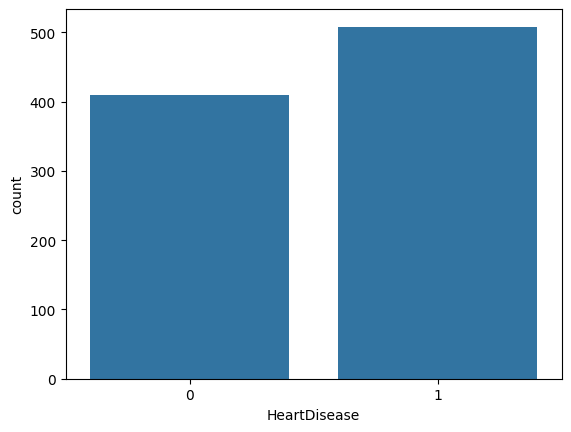

In [156]:
sns.countplot(x=df['HeartDisease'])

In [157]:
df.isnull().sum()

,0
Age,0
Sex,0
ChestPainType,0
RestingBP,0
Cholesterol,0
FastingBS,0
RestingECG,0
MaxHR,0
ExerciseAngina,0
Oldpeak,0


In [158]:
df_copy = df.copy()

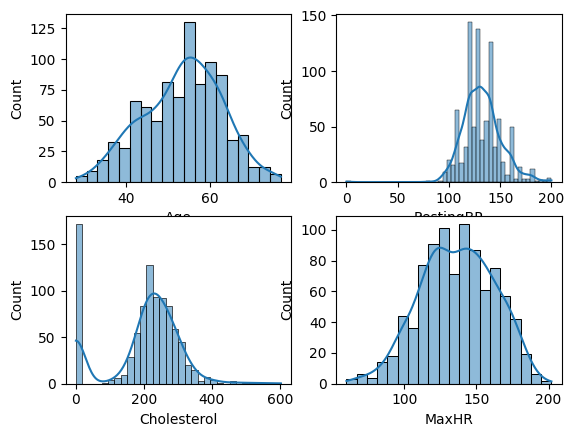

In [159]:
#Create the function to plot the data
def plot(var,num):
  plt.subplot(2,2,num)
  sns.histplot(df_copy[var],kde=True)
plot('Age',1)
plot('RestingBP',2)
plot('Cholesterol',3)
plot('MaxHR',4)

In [160]:
df_copy['Cholesterol'].value_counts()

,count
Cholesterol,
0,172
254,11
220,10
223,10
204,9
...,...
353,1
278,1
157,1


In [161]:
ch_mean = df_copy.loc[df['Cholesterol'] != 0,'Cholesterol'].mean()

In [162]:
df_copy['Cholesterol'] = df_copy['Cholesterol'].replace(0,ch_mean)
df_copy['Cholesterol'] = df_copy['Cholesterol'].round(2)

In [163]:
df_copy['Cholesterol'].value_counts()

,count
Cholesterol,
244.64,172
254.00,11
220.00,10
223.00,10
204.00,9
...,...
353.00,1
278.00,1
157.00,1


In [164]:
df_copy['RestingBP'].value_counts()

,count
RestingBP,
120,132
130,118
140,107
110,58
150,55
...,...
101,1
117,1
192,1


In [165]:
rp_mean=df_copy.loc[df_copy['RestingBP'] != 0, 'RestingBP'].mean()
df_copy['RestingBP'] = df_copy['RestingBP'].replace(0,rp_mean)
df_copy['RestingBP'] = df_copy['RestingBP'].round(2)

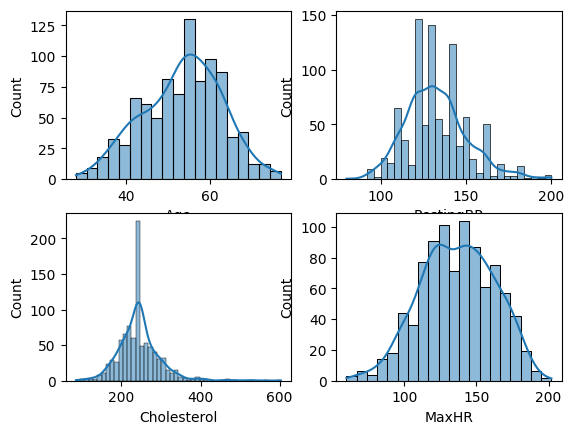

In [166]:
#Let's see how data distribution
plot('Age',1)
plot('RestingBP',2)
plot('Cholesterol',3)
plot('MaxHR',4)

<Axes: xlabel='Sex', ylabel='count'>

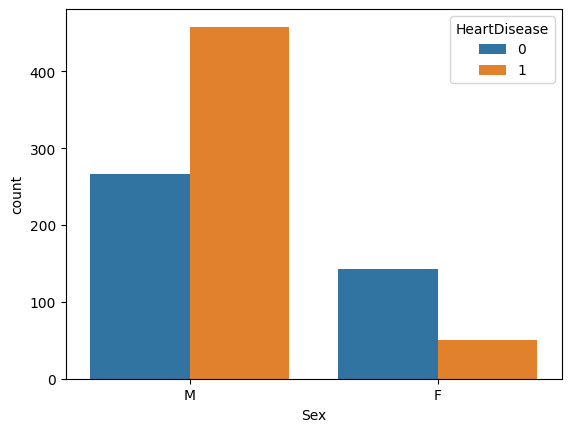

In [167]:
sns.countplot(x=df_copy['Sex'],hue= df['HeartDisease'])

<Axes: xlabel='ChestPainType', ylabel='count'>

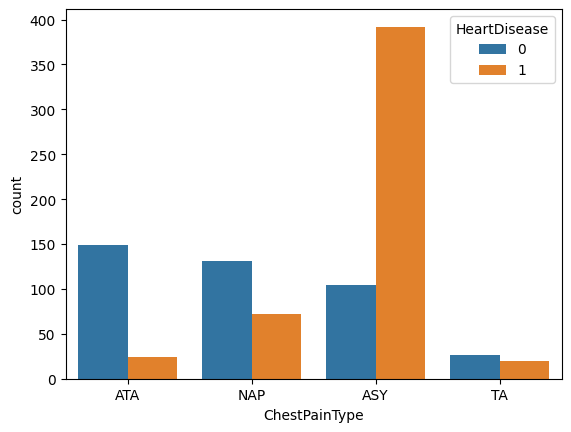

In [168]:
sns.countplot(x=df_copy['ChestPainType'],hue = df_copy['HeartDisease'])

<Axes: xlabel='FastingBS', ylabel='count'>

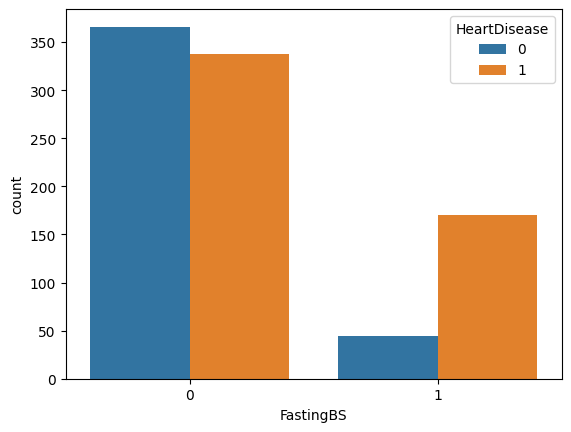

In [169]:
sns.countplot(x=df_copy['FastingBS'],hue = df_copy['HeartDisease'])

<Axes: xlabel='HeartDisease', ylabel='Cholesterol'>

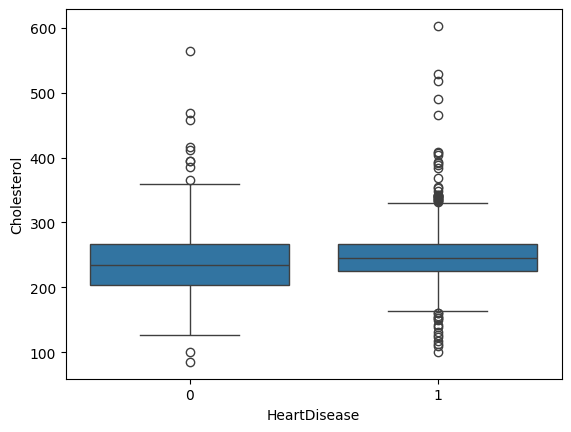

In [170]:
sns.boxplot(x='HeartDisease',y='Cholesterol',data=df_copy)

<Axes: >

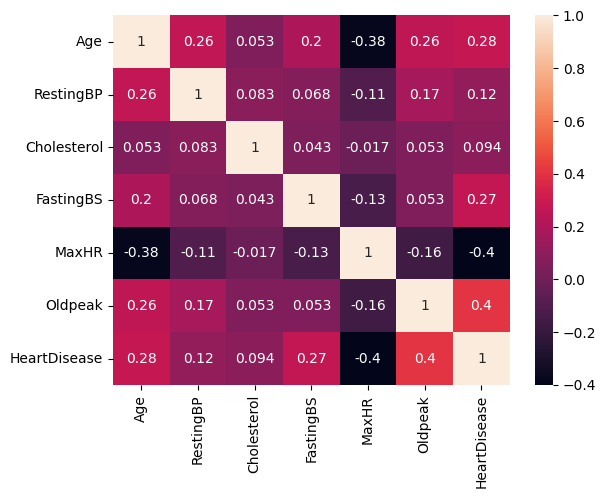

In [171]:
sns.heatmap(df_copy.corr(numeric_only=True),annot=True)

#Data preprocessing

In [172]:
numerical_cols = list(df_copy.drop(columns=['HeartDisease']).select_dtypes(include='number').columns)
cat_cols = list(df_copy.select_dtypes(exclude='number').columns)

In [173]:
X = df_copy.drop('HeartDisease',axis=1)
y = df_copy['HeartDisease']

In [174]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.33, random_state=42,stratify=y)

In [175]:
neg, pos = np.bincount(y_train)
neg, pos

(np.int64(275), np.int64(340))

In [176]:
scale_weigths = neg/pos
scale_weigths

np.float64(0.8088235294117647)

**Preporssing for Logistic Regression**

In [177]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler,OneHotEncoder
preprocesser_lr = ColumnTransformer(
    transformers=[
        #pipeline for numerical cols
        ('num',Pipeline([
            ('imputer',SimpleImputer(strategy='median')),
            ('scaler',StandardScaler())
        ]),numerical_cols),
        #Pipeline fro the categorical cols
        ('cat',Pipeline([
            ('imputer',SimpleImputer(strategy="constant",fill_value='missing')),
            ('onehot',OneHotEncoder(handle_unknown='ignore'))
        ]),cat_cols)
    ])


**Preporssing for XGBoost**

In [178]:
preprocessor_xg = ColumnTransformer(
    transformers=[
        #Pipeline - for numerical cols
        ('num', Pipeline([
            ('imputer', SimpleImputer(strategy='median'))
        ]), numerical_cols),

        #Pipeline - for Categorical cols.
        ('cat', Pipeline([
            ('imputer', SimpleImputer(strategy="constant", fill_value="Missing")),
            ('onehot', OneHotEncoder(handle_unknown='ignore'))
        ]), cat_cols)
    ])

Preprocessing for Randomforestclassifier

In [179]:
preprocesser_rf = ColumnTransformer(
    transformers=[
    ("num", Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
]), numerical_cols),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), cat_cols),
])


Preprocessing for Adaboost

```
`# This is formatted as code`
```



In [180]:

preprocesser_Ad = ColumnTransformer(
    transformers=[
    ("num", Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
]), numerical_cols),

    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ]), cat_cols),
])

Preprocessing for KNN


In [181]:
preprocesser_knn = ColumnTransformer(
    transformers=[
        #pipeline for numerical cols
        ('num',Pipeline([
            ('imputer',SimpleImputer(strategy='median')),
            ('scaler',StandardScaler())
        ]),numerical_cols),
        #Pipeline fro the categorical cols
        ('cat',Pipeline([
            ('imputer',SimpleImputer(strategy="constant",fill_value='missing')),
            ('onehot',OneHotEncoder(handle_unknown='ignore'))
        ]),cat_cols)
    ])


In [182]:
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,confusion_matrix,classification_report,precision_recall_curve
def evaluate_model(model_name,model,X_test,y_test,threshold=0):
  y_pred_prob = model.predict_proba(X_test)[:,1]
  if threshold:
    y_pred = (y_pred_prob>threshold).astype(int)
  else:
    y_pred = model.predict(X_test)
   #Metrics
  accuracy     = accuracy_score(y_test, y_pred)    #Overall model's preformance
  precision    = precision_score(y_test, y_pred)   #When the model says 1, how oftenly is it actually 1.
  recall       = recall_score(y_test, y_pred)      #of the actual 1 how many did the model catches
  f1           = f1_score(y_test, y_pred)          #Harmonic mean of precision and recall

  conf_matrix   = confusion_matrix(y_test, y_pred)
  class_report  = classification_report(y_test, y_pred)

  print(f"{model_name} Metrics:")
  if threshold is not None: # Only print threshold if provided
    print(f"Used Threshold : {threshold:.2f}")
  print(f"Accuracy : {accuracy:.2f}")
  print(f"Precision : {precision:.2f}")
  print(f"Recall : {recall:.2f}")
  print(f"F1 : {f1:.2f}")
  print()
  print(f"{model_name} Classification Report:")
  print(class_report)


  #Plotting confusion matrix
  sns.heatmap(conf_matrix, annot=True, fmt="d")
  plt.title(f"{model_name} Confusion Matrix")
  plt.ylabel("Actual Values")
  plt.xlabel("Predicted Values")
  plt.show()


  #Plotting ROC-AUC curve
  precisions, recalls, threshold = precision_recall_curve(y_test, y_pred_prob)
  plt.plot(recalls, precisions)
  plt.xlabel("Recall")
  plt.ylabel("Precision")
  plt.title(f"{model_name} Precision-Recall Curve")
  plt.show()

In [183]:
from sklearn.model_selection import StratifiedKFold, cross_validate
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {'roc_auc':'roc_auc', 'accuracy':'accuracy', 'precision':'precision', 'recall':'recall', 'f1':'f1'}

In [184]:
#Logistic Regression
from sklearn.linear_model import LogisticRegression
lr_cv_pipeline = Pipeline([
    ('preprocessor', preprocesser_lr),
    ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42))
])

In [185]:
from xgboost import XGBClassifier
xgb_cv_pipeline = Pipeline([
    ('preprocessor', preprocessor_xg),
    ('classifier', XGBClassifier(
        n_estimators=300, max_depth=5, learning_rate=0.1,
        scale_pos_weight=scale_weigths,random_state=42
    ))
])

In [186]:
from sklearn.ensemble import RandomForestClassifier
rf_cv_pipeline = Pipeline([
    ('preprocessor', preprocesser_rf),
    ('classifier', RandomForestClassifier(
        n_estimators=300, max_depth=5,
        class_weight="balanced",random_state=42
    ))
])

In [187]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier
ad_cv_pipeline = Pipeline([
    ('preprocessor', preprocesser_Ad),
    ('classifier', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=1, class_weight="balanced"),
        n_estimators=300,learning_rate=0.1,random_state=42
    ))
])

In [188]:

knn_cv_pipeline = Pipeline([
    ('preprocessor', preprocesser_knn),
    ('classifier', AdaBoostClassifier(
        estimator=DecisionTreeClassifier(
            max_depth=1,
            class_weight="balanced"
        ),
        n_estimators=300,
        learning_rate=0.1,
        random_state=42
    ))
])

In [189]:
for cv_name, pipe in [("Logistic Regression", lr_cv_pipeline),
                      ("XGBoost", xgb_cv_pipeline),('Random Forest',rf_cv_pipeline),('Adabost',ad_cv_pipeline),('KNN',knn_cv_pipeline)]:

                      cv_results = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)

                      print(cv_name)
                      print(f"ROC-AUC : {cv_results['test_roc_auc'].mean():.4f}")
                      print(f"Accuracy : {cv_results['test_accuracy'].mean():.4f}")
                      print(f"Precision : {cv_results['test_precision'].mean():.4f}")
                      print(f"Recall : {cv_results['test_recall'].mean():.4f}")
                      print(f"F1 : {cv_results['test_f1'].mean():.4f}")
                      print()

Logistic Regression
ROC-AUC : 0.9127
Accuracy : 0.8341
Precision : 0.8615
Recall : 0.8353
F1 : 0.8480

XGBoost
ROC-AUC : 0.9002
Accuracy : 0.8390
Precision : 0.8402
Recall : 0.8765
F1 : 0.8573

Random Forest
ROC-AUC : 0.9139
Accuracy : 0.8309
Precision : 0.8359
Recall : 0.8647
F1 : 0.8495

Adabost
ROC-AUC : 0.9162
Accuracy : 0.8260
Precision : 0.8662
Recall : 0.8118
F1 : 0.8376

KNN
ROC-AUC : 0.9162
Accuracy : 0.8260
Precision : 0.8662
Recall : 0.8118
F1 : 0.8376



In [191]:

from sklearn.pipeline import Pipeline
baseline_model = Pipeline([
    ('preprocessor', preprocesser_lr),
    ('classifier', LogisticRegression(class_weight= "balanced"))
])
baseline_model.fit(X_train, y_train)


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['Age', 'RestingBP',
                                                   'Cholesterol', 'FastingBS',
                                                   'MaxHR', 'Oldpeak']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Sex', 'ChestPainType',
                                                   'RestingECG',
                                                   'ExerciseAngina',
                                                   'ST_Slope'])])),
                ('classifier', LogisticRegression(class_weight='balanced'))])

In [193]:
from sklearn.pipeline import Pipeline
rf_pipeline = Pipeline([
    ('preprocessor', preprocesser_rf),
    ('classifier', RandomForestClassifier(n_estimators=300, class_weight="balanced",
        random_state=42, n_jobs=-1))
])
rf_pipeline.fit(X_train, y_train)


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['Age', 'RestingBP',
                                                   'Cholesterol', 'FastingBS',
                                                   'MaxHR', 'Oldpeak']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Sex', 'ChestPainType',
                                                   'RestingECG',
                                                   'ExerciseAngina',
                                                   'ST_Slope'])])),
                ('classifier',
                 RandomForestClassifier(class_weight='balanced',
                                        n_estimators=300, n_jobs=-1,
                                        random_state=42))])

Random Forest Model Metrics:
Used Threshold : 0.00
Accuracy : 0.90
Precision : 0.90
Recall : 0.92
F1 : 0.91

Random Forest Model Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.87      0.88       135
           1       0.90      0.92      0.91       168

    accuracy                           0.90       303
   macro avg       0.90      0.89      0.90       303
weighted avg       0.90      0.90      0.90       303



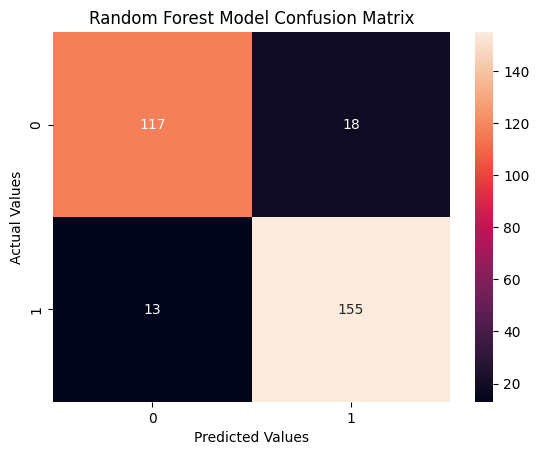

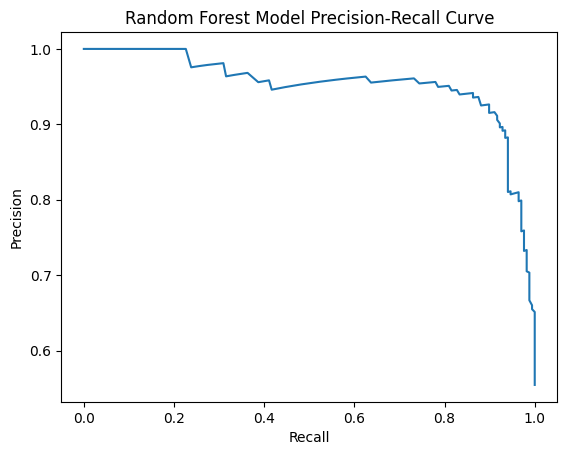

In [194]:
evaluate_model("Random Forest Model", rf_pipeline ,X_test, y_test)

In [195]:
Ad_pipeline = Pipeline([
    ('preprocessor', preprocesser_Ad),
    ('classifier', AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1, class_weight="balanced"),
        n_estimators=200,
        learning_rate=0.5,
        random_state=42,))
])
Ad_pipeline.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['Age', 'RestingBP',
                                                   'Cholesterol', 'FastingBS',
                                                   'MaxHR', 'Oldpeak']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Sex', 'ChestPainType',
                                                   'RestingECG',
                                                   'ExerciseAngina',
                                                   'ST_Slope'])])),
                ('classifier',
                 AdaBoostClassifier(estimator=DecisionTreeClassifier(class_weight='balanced',
                                                                     max_depth=1),
                                    learning_rate=0.5, n_estimators=200,
                                    random_state=42))])

Ada boost Model Metrics:
Used Threshold : 0.00
Accuracy : 0.88
Precision : 0.90
Recall : 0.88
F1 : 0.89

Ada boost Model Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.88      0.87       135
           1       0.90      0.88      0.89       168

    accuracy                           0.88       303
   macro avg       0.88      0.88      0.88       303
weighted avg       0.88      0.88      0.88       303



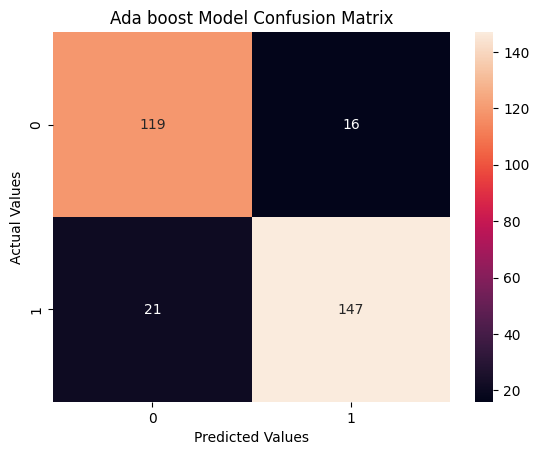

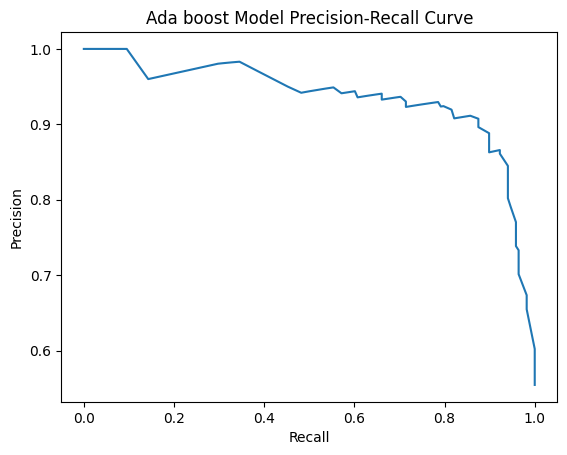

In [196]:
evaluate_model("Ada boost Model", Ad_pipeline ,X_test, y_test)

In [197]:
xg_model = Pipeline([
    ('preprocessor', preprocessor_xg),
    ('classifier', XGBClassifier(learning_rate=0.1,
        scale_pos_weight=scale_weigths,random_state=42))
])
xg_model.fit(X_train, y_train)


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['Age', 'RestingBP',
                                                   'Cholesterol', 'FastingBS',
                                                   'MaxHR', 'Oldpeak']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Missing',
                                                                                 strategy='constant')),
                                                                  ('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Sex', '...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=None, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=None, n_jobs=None,
                               num_parallel_tree=None, ...))])

XG boost Model Metrics:
Used Threshold : 0.00
Accuracy : 0.87
Precision : 0.90
Recall : 0.87
F1 : 0.88

XG boost Model Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.88      0.86       135
           1       0.90      0.87      0.88       168

    accuracy                           0.87       303
   macro avg       0.87      0.88      0.87       303
weighted avg       0.88      0.87      0.87       303



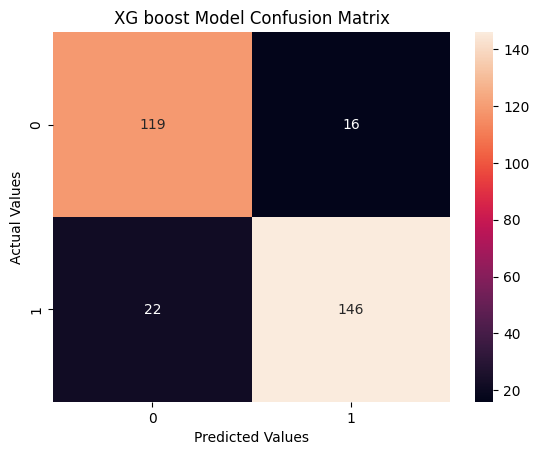

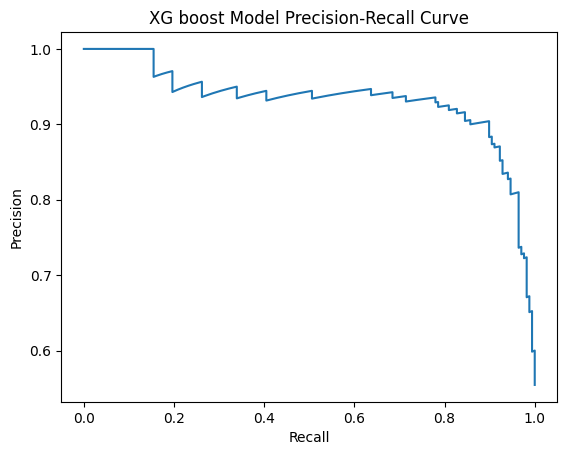

In [199]:
evaluate_model("XG boost Model", xg_model ,X_test, y_test)

In [212]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import randint

# Define the hyperparameter search space tailored specifically for Random Forest
rf_param_grid = {
    'classifier__n_estimators': randint(100, 500),
    'classifier__max_depth': [None, 5, 10, 15, 20],
    'classifier__min_samples_split': randint(2, 11),
    'classifier__min_samples_leaf': randint(1, 11),
    'classifier__bootstrap': [True, False]
}

# Set up RandomizedSearchCV using the Random Forest pipeline
rf_random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=rf_param_grid,
    n_iter=50,  # Number of parameter settings sampled
    cv=cv,
    scoring='average_precision',
    n_jobs=-1,
    verbose=1,
    random_state=42
)

# Run the hyperparameter tuning on the training data
rf_random_search.fit(X_train, y_train)
print(f"Best Hyperparameters for Random Forest: {rf_random_search.best_params_}")
print(f"Best Average Precision Score: {rf_random_search.best_score_:.4f}")

Fitting 5 folds for each of 50 candidates, totalling 250 fits
Best Hyperparameters for Random Forest: {'classifier__bootstrap': True, 'classifier__max_depth': 15, 'classifier__min_samples_leaf': 3, 'classifier__min_samples_split': 4, 'classifier__n_estimators': 246}
Best Average Precision Score: 0.9192


Tuned Random Forest Model Metrics:
Used Threshold : 0.00
Accuracy : 0.90
Precision : 0.91
Recall : 0.92
F1 : 0.91

Tuned Random Forest Model Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.88      0.89       135
           1       0.91      0.92      0.91       168

    accuracy                           0.90       303
   macro avg       0.90      0.90      0.90       303
weighted avg       0.90      0.90      0.90       303



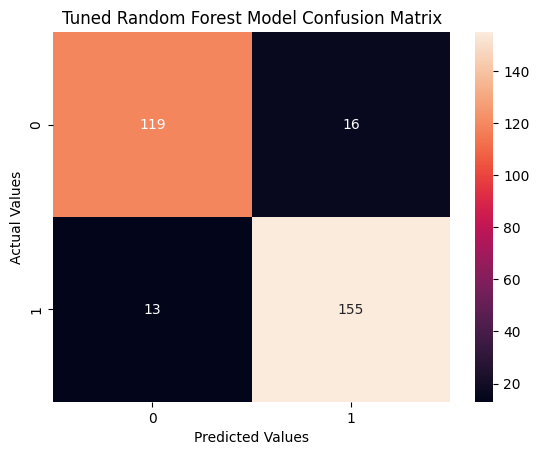

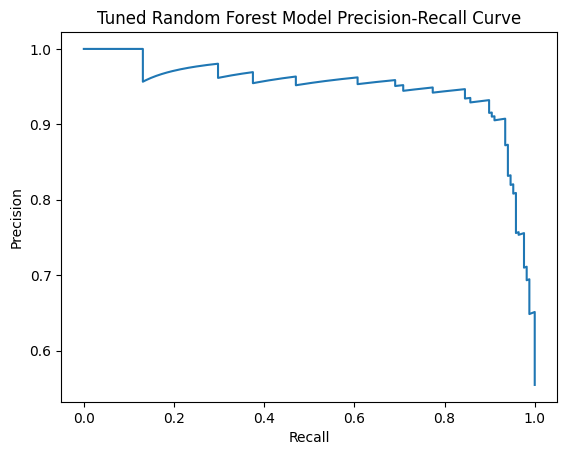

In [213]:
# Evaluate the tuned Random Forest model on the test dataset
best_rf_model = rf_random_search.best_estimator_
evaluate_model("Tuned Random Forest Model", best_rf_model, X_test, y_test)

Logistic Regression Metrics:
Used Threshold : 0.00
Accuracy : 0.87
Precision : 0.89
Recall : 0.88
F1 : 0.89

Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.87      0.86       135
           1       0.89      0.88      0.89       168

    accuracy                           0.87       303
   macro avg       0.87      0.87      0.87       303
weighted avg       0.87      0.87      0.87       303



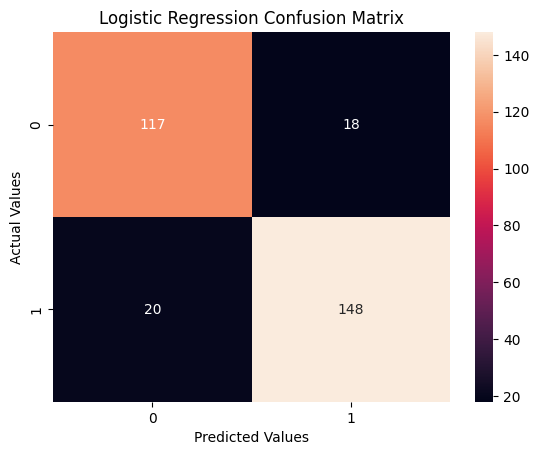

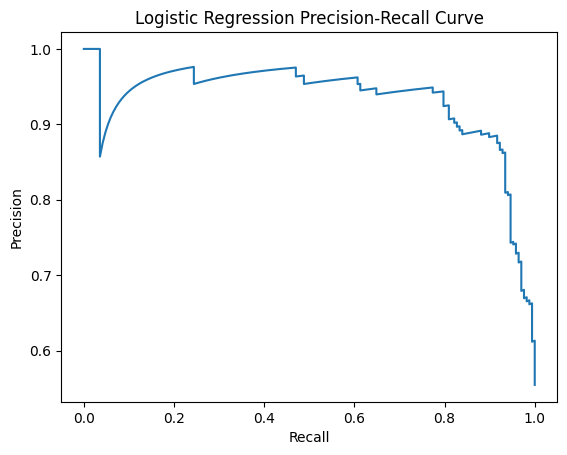

In [207]:
evaluate_model("Logistic Regression", baseline_model, X_test, y_test)

Random Forest Model Metrics:
Used Threshold : 0.00
Accuracy : 0.90
Precision : 0.90
Recall : 0.92
F1 : 0.91

Random Forest Model Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.87      0.88       135
           1       0.90      0.92      0.91       168

    accuracy                           0.90       303
   macro avg       0.90      0.89      0.90       303
weighted avg       0.90      0.90      0.90       303



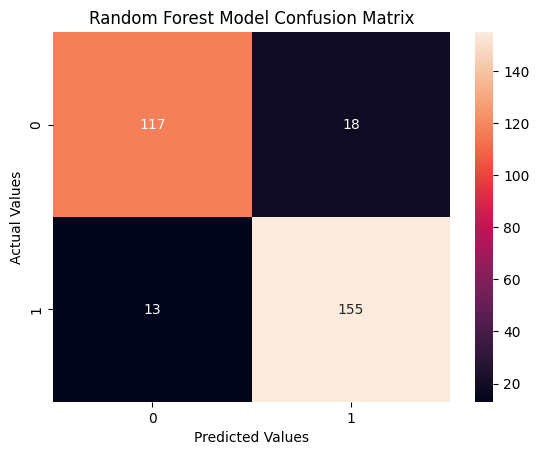

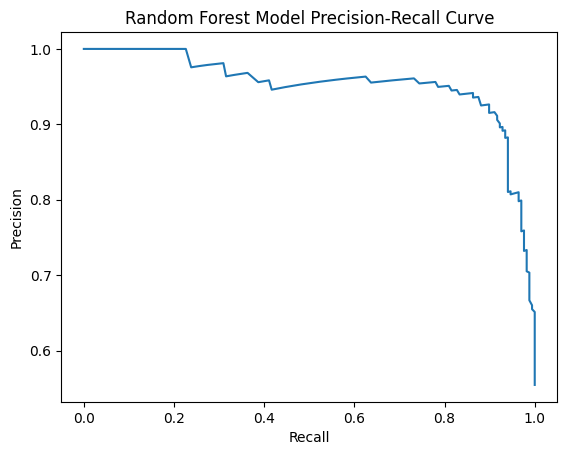

In [209]:
evaluate_model("Random Forest Model", rf_pipeline ,X_test, y_test)

Ada boost Model Metrics:
Used Threshold : 0.00
Accuracy : 0.88
Precision : 0.90
Recall : 0.88
F1 : 0.89

Ada boost Model Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.88      0.87       135
           1       0.90      0.88      0.89       168

    accuracy                           0.88       303
   macro avg       0.88      0.88      0.88       303
weighted avg       0.88      0.88      0.88       303



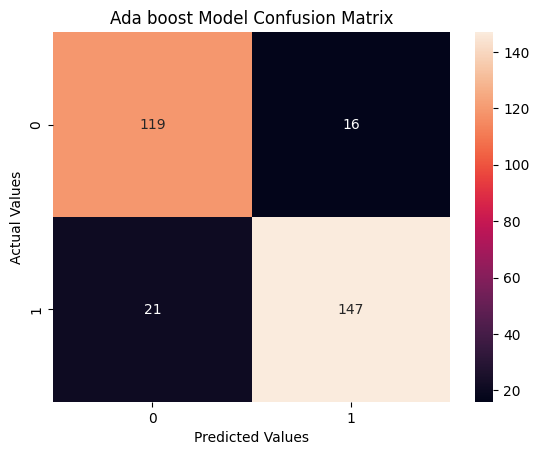

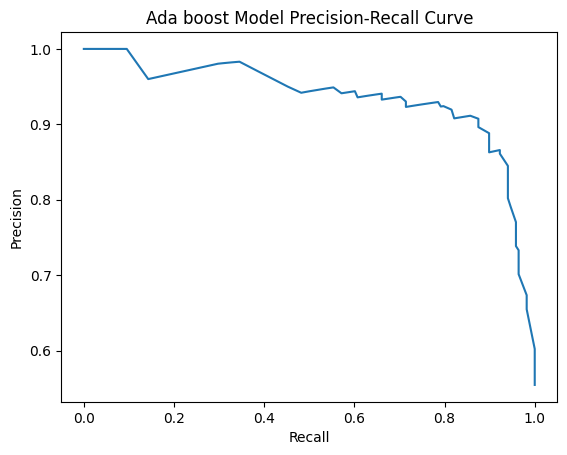

In [210]:
evaluate_model("Ada boost Model", Ad_pipeline ,X_test, y_test)

In [ ]:
import pickle

# Define the filename to save the model
model_filename = 'best_heart_disease_rf_model.pkl'

# Save the best trained Random Forest model to a pickle file
with open(model_filename, 'wb') as file:
    pickle.dump(best_rf_model, file)

print(f"Successfully saved the best model to {model_filename}!")

In [ ]:
'''# End-to-End Heart Disease Prediction Model Development Process

This summary outlines the systematic process followed to build, optimize, and save the best-performing machine learning model for predicting heart disease.

---

### 1. Data Ingestion & Initial Exploration
* **Loading the Dataset:** The dataset (`heart.csv`) containing 918 observations and 12 features was successfully loaded using `pandas`.
* **Statistical Inspection:** Checked structural characteristics using `.shape`, `.info()`, and `.describe()`. No duplicate records were found.
* **Target Variable Analysis:** Analyzed `HeartDisease` distribution, finding a balanced target with 508 cases of heart disease (1) and 410 healthy patients (0).

### 2. Exploratory Data Analysis (EDA) & Data Cleaning
* **Visualizing Distributions:** Plotted histograms and density curves for continuous variables such as `Age`, `RestingBP`, `Cholesterol`, and `MaxHR`.
* **Handling Erroneous Values & Outliers:**
  * **Cholesterol:** Found 172 records with missing/implausible `0` values. Replaced them with the mean value of the non-zero cholesterol records (~244.64).
  * **RestingBP:** Found a record with a `0` value. Replaced it with the mean value of non-zero blood pressure records (~132.54).
* **Categorical Feature Association:** Explored correlation patterns and categorical variables (`Sex`, `ChestPainType`, `FastingBS`) against the target variable using count plots.

### 3. Feature & Target Splitting
* Separated the independent features (`X`) from the target variable (`y`, `HeartDisease`).
* Stratified split the data into a **Training Set (67%)** and a **Holdout Test Set (33%)** to preserve class proportions and ensure honest evaluation.

### 4. Modular Preprocessing & Pipeline Architecture
Using Scikit-Learn's `ColumnTransformer` and `Pipeline`, custom preprocessing pipelines were constructed to prevent data leakage during Cross-Validation:
* **Numerical Features:** Imputed missing values using the `median` strategy and applied `StandardScaler` (where required, e.g., Logistic Regression & KNN).
* **Categorical Features:** Imputed missing entries using `most_frequent` or constant values and encoded them using `OneHotEncoder`.

### 5. Cross-Validation & Baseline Model Selection
Evaluated 5 distinct architectures using **5-Fold Stratified Cross-Validation** on the training set, optimizing for multiple metrics:
* Logistic Regression
* XGBoost
* **Random Forest (Best Performing)**
* AdaBoost
* K-Nearest Neighbors (KNN)

*Random Forest* emerged as the most robust candidate, showcasing an excellent balance of Precision, Recall, and overall ROC-AUC.

### 6. Hyperparameter Optimization (Tuning)
* Set up a hyperparameter tuning space specifically for the **Random Forest** classifier, testing ranges for `n_estimators`, `max_depth`, `min_samples_split`, `min_samples_leaf`, and `bootstrap`.
* Executed `RandomizedSearchCV` over 50 iterations with stratified cross-validation, optimizing specifically for **Average Precision**.
* **Best Hyperparameters Found:**
  * `bootstrap`: True
  * `max_depth`: 15
  * `min_samples_leaf`: 3
  * `min_samples_split`: 4
  * `n_estimators`: 246

### 7. Holdout Test Set Evaluation
The final tuned Random Forest model was evaluated on the unseen holdout test set to ensure strong generalization:
* **Accuracy:** 90%
* **Precision:** 91%
* **Recall:** 92%
* **F1-Score:** 91%
* **Visual Diagnostics:** Plotted a Confusion Matrix (only 13 false negatives, 16 false positives out of 303 cases) and a Precision-Recall Curve to confirm high reliability.

### 8. Model Deployment Export
* The final, complete Pipeline (incorporating both the data preprocessing steps and the tuned Random Forest estimator) was serialized and saved to a file named `best_heart_disease_rf_model.pkl` using Python's `pickle` library for immediate deployment downstream.'''